# 06 - Embeddings for Retrieval: The Architecture Behind RAG

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Make sure we get outputs from a probabilitistic model each time (for reproducibility)
np.random.seed(1515)

## Deciding on Relevance

`ai_resources/agent_primer/02-tokens-and-context.md` and `06-memory-systems.md` already told you agents pull outside information into context via **Retrieval-Augmented Generation (RAG)** whenever it can't all fit in the context window at once. It also stressed the importance of good retrieval quality as your data grows, like ours would over the course of a season. 

We didn't cover how a system actually decides what's "relevant." That decision is not made by another LLM call reading every candidate document, because that would be far too costly at scale. It's made by comparing vectors. Specifically, the same kind of vectors `01-tokenization-and-embeddings.ipynb` built out of an embedding matrix.

One note on terminology: the model that turns text into these vectors is an **encoder** (no causal mask, every token sees the whole input), not the text-generating decoder-only kind. The LLM that eventually *reads* the retrieved text is a separate, decoder-only model. See `03-transformer-block-and-history.ipynb` for a breakdown on the difference between encoders and decoders. 

## Comparing Vectors by Direction: Cosine Similarity

Recall from `linear_algebra_primer/01-vectors.ipynb`: the dot product of two vectors measures how much they point in the same direction, and a vector's magnitude (norm) is its length. **Cosine similarity** combines both ideas into a single, bounded score: the dot product of two vectors, divided by the product of their magnitudes.

$$S_C(a, b) = \frac{a \cdot b}{\|a\| \, \|b\|}$$

Dividing by both magnitudes is what makes this a similarity score about *meaning* rather than *length*: a raw dot product would rate a long document's embedding as more "similar" to everything just because it's long, the same way a bigger vector naturally produces bigger dot products regardless of direction. The result always falls between $-1$ (pointing in exactly opposite directions) and $1$ (pointing in exactly the same direction), with $0$ meaning unrelated (perpendicular).

In [2]:
def cosine_similarity(a, b):
    return (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Sanity check against the three cases the formula promises, before trusting it on
# anything more complicated:
parallel = np.array([2.0, 0.0])
same_direction_different_length = np.array([6.0, 0.0])
perpendicular = np.array([0.0, 3.0])
opposite = np.array([-4.0, 0.0])

print(f"Same direction, different length: {cosine_similarity(parallel, same_direction_different_length):.3f}  (expect ~1.0)")
print(f"Perpendicular:                    {cosine_similarity(parallel, perpendicular):.3f}  (expect ~0.0)")
print(f"Opposite direction:               {cosine_similarity(parallel, opposite):.3f}  (expect ~-1.0)")

Same direction, different length: 1.000  (expect ~1.0)
Perpendicular:                    0.000  (expect ~0.0)
Opposite direction:               -1.000  (expect ~-1.0)


The first pair scores essentially 1.0 despite one vector being three times longer than the other, showing length didn't matter, only direction did.

## A Hand-Designed Retrieval Corpus

Real document embeddings would have to be learned, so we'll hand-design a few tiny ones along interpretable axes instead, specifically so we can verify retrieval actually finds the right thing for a reason we can check.

Each toy scouting note below gets a 4-dimensional embedding on the axes `[climbing-signal, autonomous-signal, defense-signal, scoring-signal]`, which is a stand-in for whatever a real embedding model would have learned those dimensions to mean.

In [3]:
labels = ["Team 1114", "Team 2056", "Team 254", "Team 5940", "Team 4930"]
documents = [
    "Team 1114 climbs the wall reliably every match",
    "Team 2056 has a fast, consistent autonomous routine",
    "Team 254 plays aggressive defense in the endgame",
    "Team 5940 racks up a high volume of top teleop scores",
    "Team 4930 struggles to reach the tower in the final seconds",
]

# axes: [climbing-signal, autonomous-signal, defense-signal, scoring-signal]
doc_embeddings = np.array([
    [3.0, 0.1, 0.0, 0.2],   # Team 1114 - climbing
    [0.1, 3.0, 0.0, 0.3],   # Team 2056 - autonomous
    [0.0, 0.1, 3.0, 0.1],   # Team 254  - defense
    [0.1, 0.2, 0.0, 3.0],   # Team 5940 - scoring
    [2.6, 0.0, 0.2, 0.0],   # Team 4930 - climbing (a struggling climber, but still climbing)
])

for label, doc in zip(labels, documents):
    print(f"{label:10s} {doc}")

Team 1114  Team 1114 climbs the wall reliably every match
Team 2056  Team 2056 has a fast, consistent autonomous routine
Team 254   Team 254 plays aggressive defense in the endgame
Team 5940  Team 5940 racks up a high volume of top teleop scores
Team 4930  Team 4930 struggles to reach the tower in the final seconds


Now a query, phrased with none of the words `"climb"` or `"climbing"` in it at all. This is the same test `01`'s `climbable`/`scoreboard` and `02`'s hand-built relationships ran, just for retrieval instead of tokenization or attention.

In [4]:
query = "Which teams are strong at scaling to the top of the field element?"
query_embedding = np.array([2.8, 0.1, 0.0, 0.1])   # hand-designed: mostly climbing-signal

similarities = np.array([cosine_similarity(query_embedding, d) for d in doc_embeddings])
ranking = np.argsort(similarities)[::-1]

print(f'Query: "{query}"\n')
print("Ranked by cosine similarity:")
for i in ranking:
    print(f"  {similarities[i]:.3f}  {labels[i]:10s} {documents[i]}")

Query: "Which teams are strong at scaling to the top of the field element?"

Ranked by cosine similarity:
  1.000  Team 1114  Team 1114 climbs the wall reliably every match
  0.996  Team 4930  Team 4930 struggles to reach the tower in the final seconds
  0.072  Team 2056  Team 2056 has a fast, consistent autonomous routine
  0.071  Team 5940  Team 5940 racks up a high volume of top teleop scores
  0.002  Team 254   Team 254 plays aggressive defense in the endgame


Team 1114 and Team 4930 rank far above everyone else, at essentially 1.0 and 0.99. This occurs despite the query sharing **zero literal words** with either document (`"scaling"` and `"climbs"`, `"field element"` and `"wall"`/`"tower"` are different words entirely). Nothing about string-matching put them on top. Both the query and both documents were hand-designed to point in roughly the same direction on the climbing axis, and cosine similarity found exactly that. It's the same way `02`'s `it` found `robot` by dot product, not by the two words looking alike.

## Why a Keyword Search Would Get This Wrong

It's worth seeing the alternative fail, not just seeing embeddings succeed. A **naive keyword search** (count how many words a query and a document have in common, rank by that count) is the obvious thing to try before reaching for embeddings at all.

In [5]:
STOPWORDS = {"a", "an", "the", "is", "are", "at", "of", "to", "in", "on",
             "for", "which", "teams", "team"}

def keywords(text):
    return {word.strip(".,?").lower() for word in text.split()} - STOPWORDS

query_keywords = keywords(query)
overlaps = np.array([len(query_keywords & keywords(doc)) for doc in documents])
keyword_ranking = np.argsort(overlaps)[::-1]

print(f"Query keywords: {query_keywords}\n")
print("Ranked by naive keyword overlap:")
for i in keyword_ranking:
    shared = query_keywords & keywords(documents[i])
    print(f"  overlap={overlaps[i]}  shared={shared or '{}'}  {labels[i]:10s} {documents[i]}")

Query keywords: {'strong', 'scaling', 'element', 'top', 'field'}

Ranked by naive keyword overlap:
  overlap=1  shared={'top'}  Team 5940  Team 5940 racks up a high volume of top teleop scores
  overlap=0  shared={}  Team 4930  Team 4930 struggles to reach the tower in the final seconds
  overlap=0  shared={}  Team 254   Team 254 plays aggressive defense in the endgame
  overlap=0  shared={}  Team 2056  Team 2056 has a fast, consistent autonomous routine
  overlap=0  shared={}  Team 1114  Team 1114 climbs the wall reliably every match


Keyword overlap ranks **Team 5940 first**, even though they're a scoring-focused team with no climbing signal at all, purely because its note happens to contain the word `"top"` (as in "top teleop scores"), which coincidentally also appears in the query ("top of the field element"). Every other document, including the two actually-relevant climbing notes, ties at zero shared words. A keyword search has no way to know `"scaling"` and `"climbs"` mean related things, and no way to know `"top"` means something completely different in the two contexts it appears in. 

It's the ordinary failure mode of matching strings instead of meaning, and it's exactly why `agent_primer/06-memory-systems.md` reaches for RAG instead of `grep`-ing a season of notes for exact phrases.

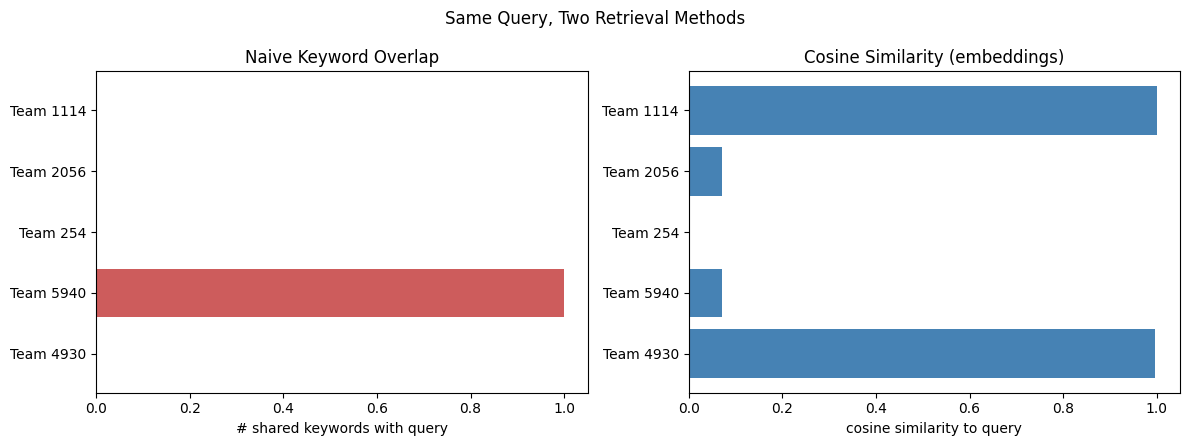

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].barh(labels, overlaps, color='indianred')
axes[0].set_title('Naive Keyword Overlap')
axes[0].set_xlabel('# shared keywords with query')
axes[0].invert_yaxis()

axes[1].barh(labels, similarities, color='steelblue')
axes[1].set_title('Cosine Similarity (embeddings)')
axes[1].set_xlabel('cosine similarity to query')
axes[1].invert_yaxis()

fig.suptitle('Same Query, Two Retrieval Methods')
plt.tight_layout()
plt.show()

The method that scores highest on the left (Team 5940) scores among the *lowest* on the right, and the two methods don't even roughly agree on second place. This is the concrete version of why real RAG systems retrieve by embedding similarity and not by keyword match.

## The Whole Corpus at Once

Retrieval isn't only query-to-document. In fact, the same cosine similarity works between any two embeddings, including document-to-document. A full pairwise similarity matrix (the same style of heatmap `02` and `03` used for attention weights) shows the whole toy corpus's structure at a glance, query included.

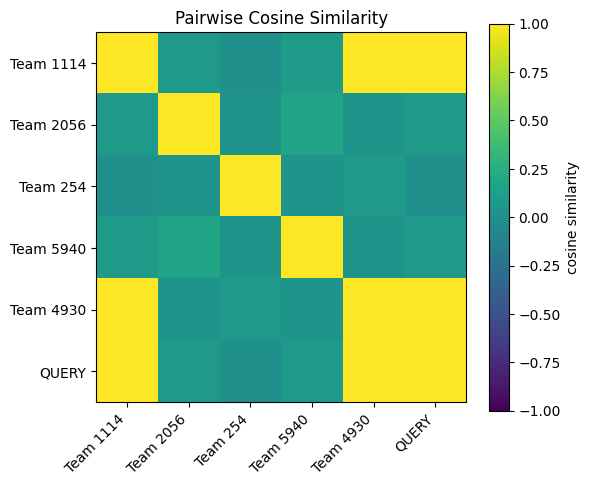

In [7]:
all_vectors = np.vstack([doc_embeddings, query_embedding])
all_labels = labels + ["QUERY"]
n = len(all_labels)

sim_matrix = np.zeros((n, n))
for i in range(n):
    for j in range(n):
        sim_matrix[i, j] = cosine_similarity(all_vectors[i], all_vectors[j])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim_matrix, cmap='viridis', vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_yticks(range(n))
ax.set_xticklabels(all_labels, rotation=45, ha='right')
ax.set_yticklabels(all_labels)
ax.set_title('Pairwise Cosine Similarity')
plt.colorbar(im, label='cosine similarity')
plt.tight_layout()
plt.show()

Team 1114, Team 4930, and QUERY form one visibly bright block in the top-left corner. They're mutually similar, and clearly separated from the other three teams, which are each closer to *themselves* than to anything else. This is what a well-formed embedding space looks like: related things cluster, unrelated things don't, and a query is just one more point you can drop into that same space and measure distances from.

## Why Real Systems Don't Compare Against Every Document

Everything above computed cosine similarity against all five documents, every time. This is fine for five documents, but a real scouting archive might hold thousands of match notes across a season, and a real production RAG system might search millions of documents. Brute-force comparison against every single one, for every query, is unsustainable at that level of data.

Real systems solve this with a **vector database** (FAISS, pgvector, Pinecone, and similar tools) built around an **approximate nearest-neighbor (ANN)** index: a data structure that organizes embeddings ahead of time so a query only has to be compared against a small, promising subset instead of everything, trading a small amount of retrieval accuracy for a large, often necessary speedup. "Approximate" does come at a real cost, with an ANN index  occasionally missing the single best match in exchange for answering in a fraction of the time brute force would take, the same kind of accuracy-for-speed trade `edge_computing_primer` covers for model compression.

## Chunking: What Actually Gets Embedded

This notebook's toy documents were conveniently short. A real season of scouting notes isn't naturally that shape. Embed an entire season as a *single* vector and it points in some blurry average direction that doesn't strongly match any specific query. Embed every individual sentence in isolation and you can lose the surrounding context that made the sentence meaningful in the first place ("they missed three times" - missed *what*, climbs or shots?).

Real RAG systems split source text into **chunks** (could be a paragraph, a single match report, a few sentences) before embedding each one separately, so retrieval can return a specific, right-sized piece of text rather than an entire document or an orphaned fragment. Chunk size is a real design decision with a real tradeoff. Chunk too small and a chunk loses the context it needs to mean anything on its own; too large and its embedding dilutes toward an unhelpful average. `agent_primer/06-memory-systems.md`'s memory-schema exercise already made this exact decision without naming it. Storing one record per team per match, rather than one record per season or one record per sentence, *is* choosing a chunk size.

## Try It Yourself

Two parts, both using the `documents`/`doc_embeddings` set above:

1. Write a new query about a *different* theme (autonomous or defense), phrased with none of the words its matching document uses. Hand-design a 4-dim embedding for it the same way `query_embedding` was built, and verify by cosine similarity that the correct document actually wins.
2. Now try the case this notebook's query didn't cover: hand-design a **6th document** whose *text* literally contains one or two of your new query's exact keywords, but whose *embedding* is designed to be irrelevant (small values on every axis that matters to your query; a decoy, the same role Team 5940 played by coincidence above, except this time on purpose). Check both rankings: does it win by keyword overlap? Does it win by cosine similarity? Write one sentence on what that tells you about which method is easier to accidentally (or deliberately) fool with wording alone.

In [8]:
# TODO: 1. write a new query for a different theme (autonomous or defense), hand-design
#          its embedding, and verify the correct document wins by cosine similarity
#       2. hand-design a 6th document that's a keyword-decoy (shares literal words with
#          your query but is embedded as irrelevant), and compare its keyword-overlap
#          rank against its cosine-similarity rank


## Resources

- Lewis, P. et al. (2020). "Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks." Already linked from `agent_primer/02-tokens-and-context.md`; revisit now with the actual similarity mechanism behind the "retrieve" step (paper).
- Johnson, J., Douze, M., & Jegou, H. (2019). "Billion-scale similarity search with GPUs." The paper behind FAISS, one of the most widely used ANN vector-search libraries named above (paper).
- [Pinecone: What is a Vector Database?](https://www.pinecone.io/learn/vector-database/) - a clear, product-neutral explanation of ANN indexing and why brute-force similarity search stops scaling (instructional).